# Preprocess v_1: làm sạch điểm GPS và chia dev/holdout

- **Tham số:** [`config.yaml`](config.yaml). Lý do và bằng chứng của từng quy tắc được tổng hợp trong [`docs/preprocess_v1.md`](../../docs/preprocess_v1.md).
- **Cách trình bày:** toàn bộ code nằm trong notebook. Mỗi bước gồm:
  1. hàm được định nghĩa ngay ở cell trước khi dùng;
  2. bằng chứng chọn ngưỡng, tính trên chính dữ liệu đang xử lý;
  3. áp dụng quy tắc rồi in mẫu kiểm tra.
- **Output:** `data/preprocess/v_1/`. Thư mục của một version là bất biến: đổi tham số thì tạo `v_2`.

Các bước:
1. Đọc raw và tìm file trùng giữa các user
2. Bỏ giá trị không hợp lệ và trùng timestamp
3. Loại file chuyến bay
4. Chọn ngưỡng spike, loại file lỗi nặng
5. Xoá spike
6. Xử lý điểm quá tốc độ
7. Giờ local và lịch làm việc
8. Coverage, tier, chia dev/holdout
9. Ghi output

Nhãn phương tiện (`labels.txt`, 69 user) **không** phải nhãn home/office. Notebook chỉ dùng nhãn này để kiểm tra chéo: một điểm có nhãn `train` thì không phải lỗi GPS.

In [1]:
import json, re, shutil, time
from datetime import date
from pathlib import Path

import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from joblib import Parallel, delayed
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from timezonefinder import TimezoneFinder

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "axes.titleweight": "bold"})

ROOT = Path.cwd().resolve().parents[1]
cfg = yaml.safe_load(Path("config.yaml").read_text())
OUT = ROOT / cfg["paths"]["out_dir"]
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
FORCE = True  # False: dừng nếu version đã có output (bảo vệ tính bất biến)
if OUT.exists() and any(OUT.iterdir()) and not FORCE:
    raise SystemExit(f"{OUT} đã tồn tại, hãy tạo version mới")
OUT.mkdir(parents=True, exist_ok=True)
rep, t0 = {"version": cfg["version"]}, time.time()
EARTH_R = 6_371_008.8  # m


def show(df, n=5):
    display(df.head(n))


def savefig(name):
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=110)

## 1. Đọc raw và tìm file trùng giữa các user

Mỗi file `.plt` có 6 dòng header, sau đó là các cột `lat, lon, 0, alt, days, date, time`. Notebook chỉ đọc `lat, lon, date, time`:
- cột `0` và `days` không mang thông tin mới (EDA mục 2);
- altitude không đáng tin (EDA mục 3).

Nhãn phương tiện được gán cho một điểm khi điểm đó nằm trong khoảng `[start, end]` của một dòng trong `labels.txt`.

In [2]:
PLT_COLS = ["lat", "lon", "zero", "alt_ft", "days", "date", "time"]


def parse_user(user_dir: Path):
    """Đọc mọi file .plt + labels.txt của 1 user. Trả về (điểm, nhãn, metadata từng file)."""
    user = int(user_dir.name)
    frames, meta = [], []
    for f in sorted((user_dir / "Trajectory").glob("*.plt")):
        df = pd.read_csv(f, skiprows=6, header=None, names=PLT_COLS, usecols=["lat", "lon", "date", "time"])
        if df.empty:
            continue
        df["ts_utc"] = pd.to_datetime(df["date"] + " " + df["time"], format="%Y-%m-%d %H:%M:%S")
        df["traj_id"] = f.stem
        # khoá nhận diện file trùng giữa các user: cùng tên, số điểm, điểm đầu, thời điểm cuối
        meta.append({"user": user, "traj_id": f.stem, "n_raw": len(df), "lat0": df.lat.iat[0],
                     "lon0": df.lon.iat[0], "t_end": df.ts_utc.iat[-1]})
        frames.append(df[["traj_id", "lat", "lon", "ts_utc"]])
    pts = pd.concat(frames, ignore_index=True)
    pts.insert(0, "user", np.int16(user))
    pts["mode"] = None
    lab = pd.DataFrame(columns=["user", "start_utc", "end_utc", "mode"])
    if (user_dir / "labels.txt").exists():
        lab = pd.read_csv(user_dir / "labels.txt", sep="\t")
        lab.columns = ["start_utc", "end_utc", "mode"]
        lab["start_utc"] = pd.to_datetime(lab["start_utc"], format="%Y/%m/%d %H:%M:%S")
        lab["end_utc"] = pd.to_datetime(lab["end_utc"], format="%Y/%m/%d %H:%M:%S")
        lab.insert(0, "user", np.int16(user))
        order = pts.ts_utc.argsort(kind="stable")
        m = pd.merge_asof(pts[["ts_utc"]].iloc[order].reset_index(), lab.sort_values("start_utc"),
                          left_on="ts_utc", right_on="start_utc", direction="backward")
        hit = m["ts_utc"] <= m["end_utc"]
        pts.loc[m["index"][hit].to_numpy(), "mode"] = m["mode"][hit].to_numpy()
    return pts, lab, pd.DataFrame(meta)


user_dirs = sorted(p for p in (ROOT / cfg["paths"]["raw_dir"]).iterdir() if p.is_dir())
res = Parallel(n_jobs=-1)(delayed(parse_user)(d) for d in user_dirs)
pts = pd.concat([r[0] for r in res], ignore_index=True)
pts["mode"] = pts["mode"].astype("category")
labels = pd.concat([r[1] for r in res if len(r[1])], ignore_index=True)
files = pd.concat([r[2] for r in res], ignore_index=True)
files["traj_key"] = files.user.astype(str) + "_" + files.traj_id
del res
rep["raw"] = {"points": len(pts), "trajs": len(files), "users": int(files.user.nunique())}
print(rep["raw"])
show(pts.sample(5, random_state=0))

/Users/nguyendat/Documents/GeolifeGPS-trajectory/.venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


{'points': 24876978, 'trajs': 18670, 'users': 182}


,user,traj_id,lat,lon,ts_utc,mode
6263122,25,20090311021122,39.976012,116.310625,2009-03-11 02:33:17,NaN
10314132,41,20090712044248,39.865115,118.533055,2009-07-12 06:57:44,NaN
22110569,153,20111015094803,40.046160,116.399788,2011-10-15 10:08:05,NaN
16645900,124,20080930203247,34.099994,92.355716,2008-10-01 01:19:39,NaN
2513268,10,20081013230418,39.141251,117.197946,2008-10-13 23:25:59,train


**File trùng giữa các user** (EDA mục 4: khoảng 12% dữ liệu). Một file được coi là trùng khi cùng tên, cùng số điểm, cùng điểm đầu và cùng thời điểm cuối với một file của user khác. Hai user có ít nhất một file chung được nối với nhau. Mỗi thành phần liên thông của đồ thị này là một **nhóm user**. Bước 8 chia tập theo nhóm để cùng một trajectory không nằm ở cả dev lẫn holdout.

In [3]:
def duplicate_groups(files: pd.DataFrame):
    files = files.copy()
    files["dup_id"] = files.groupby(["traj_id", "n_raw", "lat0", "lon0", "t_end"]).ngroup()
    files["is_cross_dup"] = files.duplicated("dup_id", keep=False)
    d = files[files.is_cross_dup]
    pairs = d.merge(d, on="dup_id").query("user_x < user_y")[["user_x", "user_y"]].drop_duplicates()
    users = np.sort(files.user.unique())
    ix = {u: i for i, u in enumerate(users)}
    m = coo_matrix((np.ones(len(pairs)), ([ix[u] for u in pairs.user_x], [ix[u] for u in pairs.user_y])),
                   shape=(len(users), len(users)))
    _, lab = connected_components(m, directed=False)
    return files, pd.Series(lab, index=users, name="group")


files, group = duplicate_groups(files)
gsize = group.map(group.value_counts())
largest = sorted(group.index[group == group.value_counts().idxmax()].tolist())
rep["cross_user_duplicates"] = {"files": int(files.is_cross_dup.sum()),
                                "points": int(files.n_raw[files.is_cross_dup].sum()),
                                "groups_gt1_user": int((group.value_counts() > 1).sum()),
                                "users_in_shared_groups": int((gsize > 1).sum()),
                                "largest_group": largest}
print(rep["cross_user_duplicates"])
d = files[files.is_cross_dup]
pairs = d.merge(d, on="dup_id").query("user_x < user_y").groupby(["user_x", "user_y"]).size()
print("Cặp user có nhiều file chung nhất:"); print(pairs.sort_values(ascending=False).head(5).to_string())
print("Ví dụ 1 file xuất hiện ở nhiều user:")
show(d[d.dup_id == d.dup_id.iloc[0]][["user", "traj_id", "n_raw", "lat0", "lon0", "t_end"]])

{'files': 1679, 'points': 2966117, 'groups_gt1_user': 18, 'users_in_shared_groups': 52, 'largest_group': [56, 78, 82, 101, 109, 110, 112, 115, 126, 128, 140, 153, 156, 163, 167]}
Cặp user có nhiều file chung nhất:
user_x  user_y
153     163       225
126     167       145
0       3         129
11      88         59
128     153        55
Ví dụ 1 file xuất hiện ở nhiều user:


,user,traj_id,n_raw,lat0,lon0,t_end
42,0,20090330005208,1328,40.000031,116.326378,2009-03-30 16:11:06
610,3,20090330005208,1328,40.000031,116.326378,2009-03-30 16:11:06


## 2. Bỏ giá trị không hợp lệ và trùng timestamp

- **Toạ độ ngoài miền xác định:** xoá.
- **Điểm có năm < 2007:** xoá. Đây là lỗi đồng hồ thiết bị (EDA mục 3).
- **Trùng `(user, ts_utc)` (2,81%):** giữ điểm đầu. Nếu không bỏ, dt = 0 làm tốc độ thành vô hạn. Giữ điểm nào cũng như nhau vì 99,5% điểm trùng giây cách điểm đầu < 10 m (EDA mục 3). Khoá theo user tương đương khoá theo file, vì file của cùng user không chồng lấn thời gian (EDA mục 2).

Sau bước này, hàm `add_kinematics` tính `dt_s`, `dist_m`, `speed_kmh` so với điểm trước **trong cùng file**. Mọi bước dùng tốc độ phía sau đều gọi lại hàm này sau khi xoá điểm.

In [4]:
def haversine(lat1, lon1, lat2, lon2):
    """Khoảng cách (m) giữa hai mảng toạ độ (độ)."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * EARTH_R * np.arcsin(np.sqrt(a))


def add_kinematics(df: pd.DataFrame) -> pd.DataFrame:
    """dt_s, dist_m, speed_kmh từ điểm trước trong cùng traj_key. df phải sort theo (user, ts_utc)."""
    k = df["traj_key"].to_numpy()
    same = k[1:] == k[:-1]
    lat, lon = df["lat"].to_numpy(), df["lon"].to_numpy()
    ts = df["ts_utc"].to_numpy().astype("datetime64[s]").astype(np.int64).astype(np.float64)
    dt = np.full(len(df), np.nan)
    dist = np.full(len(df), np.nan)
    dt[1:] = np.where(same, ts[1:] - ts[:-1], np.nan)
    dist[1:] = np.where(same, haversine(lat[:-1], lon[:-1], lat[1:], lon[1:]), np.nan)
    df["dt_s"] = dt
    df["dist_m"] = dist
    with np.errstate(divide="ignore", invalid="ignore"):
        df["speed_kmh"] = np.where(dt > 0, dist / dt * 3.6, np.nan)
    return df


def drop_trajs(df: pd.DataFrame, keys) -> pd.DataFrame:
    return df[~df.traj_key.isin(set(keys))].reset_index(drop=True)

In [5]:
v = cfg["validity"]
ok = pts.lat.between(*v["lat_range"]) & pts.lon.between(*v["lon_range"]) & (pts.ts_utc.dt.year >= v["min_year"])
print("Điểm bị loại do toạ độ / năm:"); show(pts[~ok][["user", "traj_id", "lat", "lon", "ts_utc"]], 10)
pts = pts[ok].sort_values(["user", "ts_utc"], kind="stable")
dupe = pts.duplicated(v["dedupe_key"], keep=False)
print("Ví dụ điểm trùng timestamp (giữ dòng đầu):"); show(pts[dupe][["user", "traj_id", "lat", "lon", "ts_utc"]], 4)
n1 = len(pts)
pts = pts.drop_duplicates(v["dedupe_key"], keep="first").reset_index(drop=True)
pts["traj_key"] = pts.user.astype(str) + "_" + pts.traj_id.astype(str)
pts = add_kinematics(pts.drop(columns="traj_id"))
rep["validity"] = {"invalid_coord_or_year": int((~ok).sum()), "duplicate_timestamp": int(n1 - len(pts))}
print(rep["validity"], "| còn", len(pts), "điểm | kiểm tra dt <= 0 còn lại:", int((pts.dt_s <= 0).sum()))

Điểm bị loại do toạ độ / năm:


,user,traj_id,lat,lon,ts_utc
5067886,20,20110911000506,400.166667,116.215390,2011-09-11 03:23:54
22578366,163,20000101231219,39.988992,116.327023,2000-01-01 23:12:19
22578367,163,20000101231219,39.990964,116.327041,2000-01-01 23:13:21
22578368,163,20000101231219,39.993207,116.326827,2000-01-01 23:15:23


Ví dụ điểm trùng timestamp (giữ dòng đầu):


,user,traj_id,lat,lon,ts_utc
311761,2,20081101010123,39.895867,116.272799,2008-11-01 01:09:31
311762,2,20081101010123,39.895870,116.272962,2008-11-01 01:09:31
426027,2,20090125011404,37.416330,110.771849,2009-01-25 05:26:27
426028,2,20090125011404,37.416802,110.772034,2009-01-25 05:26:27


{'invalid_coord_or_year': 4, 'duplicate_timestamp': 698900} | còn 24178074 điểm | kiểm tra dt <= 0 còn lại: 0


## 3. Loại file chuyến bay

**Quy tắc:** loại cả file khi **median tốc độ của file** > 300 km/h.

**Bằng chứng cần kiểm tra:**
- Có tồn tại một khoảng trống giữa file mặt đất và file bay hay không.
- Ngưỡng 800 km/h (tốc độ hành trình) có bỏ sót file bay hay không. Lý do: một file bay còn chứa lúc lăn bánh, cất/hạ cánh và thời gian chờ, nên median của file thấp hơn tốc độ hành trình.

median_speed_kmh
(0, 50]        17379
(50, 100]       1137
(100, 150]       102
(150, 200]        13
(200, 250]         6
(250, 300]         0
(300, 350]         0
(350, 400]         0
(400, 450]         0
(450, 500]         1
(500, 600]         2
(600, 700]         4
(700, 800]         4
(800, 900]         8
(900, 2000]        0

File có nhãn airplane (>= 30% điểm), median: [6, 663, 686, 787, 815, 852, 868]
File có nhãn train (>= 50% điểm), median max: 206.0 | p99: 183.8
Ngưỡng 300: bắt 19 file, trong đó 6/7 file có nhãn airplane
Ngưỡng 800: bắt 8 file, trong đó 3/7 file có nhãn airplane


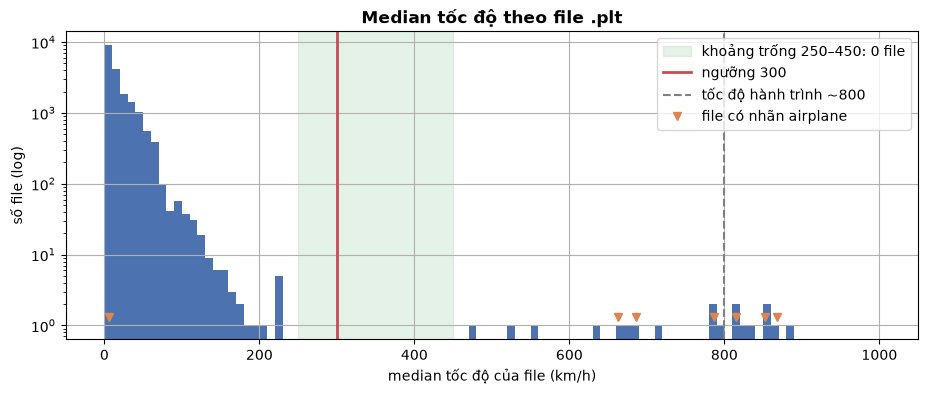

In [6]:
g = pts.groupby("traj_key", sort=False)
ts = pd.DataFrame({"user": g.user.first(), "n": g.size(), "median_speed_kmh": g.speed_kmh.median(),
                   "air": g["mode"].apply(lambda s: (s == "airplane").mean()),
                   "train": g["mode"].apply(lambda s: (s == "train").mean())})
air_lab = ts.air >= .3
print(pd.cut(ts.median_speed_kmh, [0, 50, 100, 150, 200, 250, 300, 350, 400, 450, 500, 600, 700, 800, 900, 2000])
      .value_counts().sort_index().to_string())
print("\nFile có nhãn airplane (>= 30% điểm), median:", sorted(ts.median_speed_kmh[air_lab].round().astype(int)))
print("File có nhãn train (>= 50% điểm), median max:", round(ts.median_speed_kmh[ts.train >= .5].max(), 1),
      "| p99:", round(ts.median_speed_kmh[ts.train >= .5].quantile(.99), 1))
for thr in [300, 800]:
    sel = ts.median_speed_kmh > thr
    print(f"Ngưỡng {thr}: bắt {sel.sum()} file, trong đó {(sel & air_lab).sum()}/{air_lab.sum()} file có nhãn airplane")

fig, ax = plt.subplots(figsize=(11, 4))
ax.hist(ts.median_speed_kmh.clip(upper=1000), bins=np.arange(0, 1001, 10), color="#4c72b0")
ax.set_yscale("log")
ax.axvspan(250, 450, color="#55a868", alpha=.15, label="khoảng trống 250–450: 0 file")
ax.axvline(cfg["flight"]["traj_median_speed_kmh"], color="#c44e52", lw=2, label="ngưỡng 300")
ax.axvline(800, color="grey", ls="--", label="tốc độ hành trình ~800")
ax.plot(ts.median_speed_kmh[air_lab], np.full(air_lab.sum(), 1.3), "v", color="#dd8452", label="file có nhãn airplane")
ax.set(xlabel="median tốc độ của file (km/h)", ylabel="số file (log)", title="Median tốc độ theo file .plt")
ax.legend(); savefig("flight_gap"); plt.show()

In [7]:
thr = cfg["flight"]["traj_median_speed_kmh"]
flight = ts.index[ts.median_speed_kmh > thr]
print("File bị loại:")
display(ts.loc[flight, ["n", "median_speed_kmh", "air"]].sort_values("median_speed_kmh").round(2))
rep["flight"] = {"trajs": len(flight), "points": int(ts.n[flight].sum()),
                 "labeled_airplane_trajs": int(air_lab[flight].sum())}
pts = drop_trajs(pts, flight)
print(rep["flight"], "| còn", len(pts), "điểm")

File bị loại:


,n,median_speed_kmh,air
traj_key,,,
144_20090321083221,9078,474.18,0.00
128_20100927102732,1014,525.81,0.00
128_20100523030239,465,554.63,0.00
144_20081109052637,682,637.17,0.00
128_20090222040348,447,662.89,1.00
144_20090324004422,41728,676.65,0.00
128_20080930034934,936,686.21,1.00
144_20081105011825,1240,713.30,0.00
163_20090221032640,1239,781.30,0.00


{'trajs': 19, 'points': 72863, 'labeled_airplane_trajs': 6} | còn 24105211 điểm


## 4. Chọn ngưỡng spike và loại file lỗi nặng

**Spike A → B → A:** điểm B nhảy ra xa rồi điểm C quay về gần A. B là spike khi cả ba điều kiện cùng đúng:
- tốc độ A→B > `v`;
- tốc độ B→C > `v`;
- d(A, C) < `ratio` · d(A, B).

**Bằng chứng cần kiểm tra:**
- Số spike phát hiện được có ổn định khi đổi `v` và `ratio` không.
- Bao nhiêu spike rơi vào đoạn có nhãn `train` hoặc `airplane`. Đây là các false positive chắc chắn.

In [8]:
def find_spikes(df: pd.DataFrame, speed_kmh: float, return_ratio: float) -> np.ndarray:
    """Mask điểm B kiểu A -> B -> A trong cùng file."""
    k = df["traj_key"].to_numpy()
    has_prev = np.r_[False, k[1:] == k[:-1]]
    has_next = np.r_[k[1:] == k[:-1], False]
    v_in = df["speed_kmh"].to_numpy()
    v_out = np.r_[v_in[1:], np.nan]
    lat, lon = df["lat"].to_numpy(), df["lon"].to_numpy()
    d_ac = np.r_[np.nan, haversine(lat[:-2], lon[:-2], lat[2:], lon[2:]), np.nan]
    return has_prev & has_next & (v_in > speed_kmh) & (v_out > speed_kmh) & (d_ac < return_ratio * df["dist_m"].to_numpy())


rows = []
for vv in [100, 150, 200, 300]:
    for rr in [0.1, 0.3, 0.5]:
        s = find_spikes(pts, vv, rr)
        rows.append({"v_kmh": vv, "ratio": rr, "spike_points": s.sum(), "files": pts.traj_key[s].nunique(),
                     "labeled_train_or_airplane": pts["mode"][s].isin(["train", "airplane"]).sum()})
display(pd.DataFrame(rows))

,v_kmh,ratio,spike_points,files,labeled_train_or_airplane
0,100,0.1,677,83,2
1,100,0.3,951,293,3
2,100,0.5,1196,467,3
3,150,0.1,624,32,2
4,150,0.3,710,109,2
5,150,0.5,767,154,2
6,200,0.1,604,13,0
7,200,0.3,620,28,0
8,200,0.5,630,38,0
9,300,0.1,594,3,0


**File lỗi nặng:** loại cả file khi tỉ lệ spike ≥ 1% **và** số spike ≥ 10. Bảng dưới so sánh điều kiện OR với AND trên phân bố số spike của từng file.

In [9]:
sp, cc = cfg["spike"], cfg["corrupted_traj"]
s1 = find_spikes(pts, sp["speed_kmh"], sp["return_ratio"])
n_spk = pd.Series(pts.traj_key.to_numpy()[s1]).value_counts()
spk = pd.DataFrame({"spikes": n_spk, "n": ts.n.reindex(n_spk.index)})
spk["ratio"] = spk.spikes / spk.n
print(f"{len(spk)} file có ít nhất 1 spike. Phân bố số spike / file:")
print(pd.cut(spk.spikes, [0, 1, 2, 5, 10, 100, 1e6]).value_counts().sort_index().to_string())
display(pd.concat([spk.nlargest(3, "spikes"), spk.nlargest(4, "ratio")]).drop_duplicates().round(4))
rule_or = (spk.ratio >= cc["min_spike_ratio"]) | (spk.spikes >= cc["min_spikes"])
rule_and = (spk.ratio >= cc["min_spike_ratio"]) & (spk.spikes >= cc["min_spikes"])
print("OR :", rule_or.sum(), "file ->", spk.index[rule_or].tolist())
print("AND:", rule_and.sum(), "file ->", spk.index[rule_and].tolist())

corrupted = spk.index[rule_and]
rep["corrupted"] = {"trajs": corrupted.tolist(), "points": int(ts.n[corrupted].sum()), "trajs_with_any_spike": len(spk)}
pts = add_kinematics(drop_trajs(pts, corrupted))
print(rep["corrupted"], "| còn", len(pts), "điểm")

109 file có ít nhất 1 spike. Phân bố số spike / file:
spikes
(0.0, 1.0]            99
(1.0, 2.0]             6
(2.0, 5.0]             2
(5.0, 10.0]            0
(10.0, 100.0]          1
(100.0, 1000000.0]     1


,spikes,n,ratio
62_20080926000623,577,8091,0.0713
62_20081003000004,16,4271,0.0037
68_20090517014922,3,1862,0.0016
167_20080512103623,1,5,0.2000
128_20070620130412,1,66,0.0152
153_20080614021333,1,69,0.0145


OR : 6 file -> ['62_20080926000623', '62_20081003000004', '153_20091129234104', '128_20070620130412', '153_20080614021333', '167_20080512103623']
AND: 1 file -> ['62_20080926000623']


{'trajs': ['62_20080926000623'], 'points': 8091, 'trajs_with_any_spike': 109} | còn 24097120 điểm


## 5. Xoá spike

Áp dụng quy tắc v = 150 km/h, ratio = 0,3. Lặp lại tối đa 3 lần, vì xoá một spike có thể làm lộ ra một spike khác ở ngay cạnh.

In [10]:
def remove_spikes(df: pd.DataFrame, cfg: dict):
    removed = []
    for _ in range(cfg["max_iter"]):
        s = find_spikes(df, cfg["speed_kmh"], cfg["return_ratio"])
        removed.append(int(s.sum()))
        if not s.any():
            break
        df = add_kinematics(df[~s].reset_index(drop=True))
    return df, {"spike_removed_per_iter": removed}


s = find_spikes(pts, sp["speed_kmh"], sp["return_ratio"])
i = np.flatnonzero(s)[0]
r5 = {"lat": 5, "lon": 5, "dist_m": 1, "speed_kmh": 1}
print("Ví dụ 1 spike (dòng giữa là điểm B bị xoá):")
show(pts.iloc[i - 1:i + 2][["traj_key", "ts_utc", "lat", "lon", "dt_s", "dist_m", "speed_kmh", "mode"]].round(r5))
print(f"d(A, C) = {haversine(pts.lat.iat[i - 1], pts.lon.iat[i - 1], pts.lat.iat[i + 1], pts.lon.iat[i + 1]):.0f} m")
pts, rep["spike"] = remove_spikes(pts, sp)
print(rep["spike"], "| còn", len(pts), "điểm")

Ví dụ 1 spike (dòng giữa là điểm B bị xoá):


,traj_key,ts_utc,lat,lon,dt_s,dist_m,speed_kmh,mode
9653,0_20081115010133,2008-11-15 04:00:55,40.00974,116.32226,5.0,12.5,9.0,NaN
9654,0_20081115010133,2008-11-15 04:01:05,40.01378,116.32034,10.0,477.6,171.9,NaN
9655,0_20081115010133,2008-11-15 04:01:10,40.01018,116.32173,5.0,417.8,300.8,NaN


d(A, C) = 66 m


{'spike_removed_per_iter': [133, 0]} | còn 24096987 điểm


## 6. Điểm còn tốc độ > 400 km/h

**Ngưỡng 400:** các phương tiện mặt đất có nhãn phải gần như không vượt ngưỡng này. Bảng dưới cũng đếm số điểm có nhãn `train` bị chạm vào ở từng ngưỡng.

**Cách xử lý chia hai loại:**
- **Hai phía** (tốc độ vào **và** tốc độ ra đều > 400): xoá.
- **Một phía** (chỉ tốc độ vào > 400): không xoá, chỉ đánh dấu `jump_in` và bỏ giá trị tốc độ. Lý do: các điểm phía sau nhất quán với nhau, nên vị trí sau bước nhảy là vị trí đúng. Nếu xoá điểm này, điểm kế tiếp lại thành "quá tốc độ" và bị xoá dây chuyền.

In [11]:
mode_s = pts["mode"].astype(str).to_numpy()
vi = pts.speed_kmh.to_numpy()
for m in ["train", "car", "subway", "airplane"]:
    sv = vi[mode_s == m]
    print(f"{m:9s} p99 {np.nanquantile(sv, .99):6.1f} | p99.9 {np.nanquantile(sv, .999):7.1f} | "
          + " ".join(f">{x}: {np.nanmean(sv > x):.4%}" for x in [250, 300, 400]))
display(pd.DataFrame([{"threshold_kmh": x, "points": (vi > x).sum(), "files": pts.traj_key[vi > x].nunique(),
                       "labeled_train": ((vi > x) & (mode_s == "train")).sum()} for x in [250, 300, 350, 400, 500]]))

train     p99  210.3 | p99.9   242.1 | >250: 0.0143% >300: 0.0091% >400: 0.0030%
car       p99  119.6 | p99.9   199.5 | >250: 0.0063% >300: 0.0057% >400: 0.0042%
subway    p99   94.4 | p99.9   166.4 | >250: 0.0255% >300: 0.0171% >400: 0.0104%


airplane  p99  162.0 | p99.9   655.5 | >250: 0.2538% >300: 0.2256% >400: 0.1974%


,threshold_kmh,points,files,labeled_train
0,250,9277,2043,80
1,300,8024,1576,51
2,350,7250,1258,20
3,400,6697,1039,17
4,500,5850,773,14


In [12]:
def overspeed_two_sided(df: pd.DataFrame, speed_kmh: float) -> np.ndarray:
    """Điểm có cả tốc độ vào và tốc độ ra > ngưỡng."""
    k = df["traj_key"].to_numpy()
    has_next = np.r_[k[1:] == k[:-1], False]
    v_in = df["speed_kmh"].to_numpy()
    return has_next & (v_in > speed_kmh) & (np.r_[v_in[1:], np.nan] > speed_kmh)


def handle_overspeed(df: pd.DataFrame, cfg: dict):
    removed = []
    for _ in range(cfg["max_iter"]):
        s = overspeed_two_sided(df, cfg["speed_kmh"])
        removed.append(int(s.sum()))
        if not s.any():
            break
        df = add_kinematics(df[~s].reset_index(drop=True))
    jump = (df["speed_kmh"] > cfg["speed_kmh"]).to_numpy()
    df["jump_in"] = jump
    df.loc[jump, ["dt_s", "dist_m", "speed_kmh"]] = np.nan
    return df, {"two_sided_removed_per_iter": removed, "one_sided_jumps_marked": int(jump.sum())}


ms = cfg["max_speed"]["speed_kmh"]
o = (pts.speed_kmh > ms).to_numpy()
two = overspeed_two_sided(pts, ms)
print(f"{o.sum()} điểm > {ms} km/h ở {pts.traj_key[o].nunique()} file: hai phía {two.sum()}, còn lại {(o & ~two).sum()}")
# độ dài chuỗi điểm > ngưỡng liên tiếp trong cùng file: 1 điểm = bước nhảy đơn lẻ, chuỗi dài = đoạn bay trong file hỗn hợp
k = pts.traj_key.to_numpy()
rid = np.cumsum(o & ~np.r_[False, o[:-1] & (k[1:] == k[:-1])])
run_len = pd.Series(rid[o]).value_counts()
print("Số điểm theo độ dài chuỗi liên tiếp:",
      run_len.groupby(pd.cut(run_len, [0, 1, 2, 5, 20, 1e6]), observed=True).sum().to_dict())
long_run = np.isin(rid, run_len.index[run_len > 20]) & o
print(f"Chuỗi > 20 điểm: {long_run.sum()} điểm ở {pts.traj_key[long_run].nunique()} file, nhãn:",
      pts["mode"][long_run].value_counts().loc[lambda x: x > 0].to_dict(), "| file:", pts.traj_key[long_run].unique()[:5].tolist())
single = o & ~long_run
print(f"Điểm lẻ: dt phổ biến {pts.dt_s[single].value_counts().head(3).to_dict()} | quãng nhảy median {pts.dist_m[single].median():.0f} m")
cols6 = ["traj_key", "ts_utc", "lat", "lon", "dt_s", "dist_m", "speed_kmh"]
i = np.flatnonzero(two)[0]
print("Ví dụ một chuỗi > 400 km/h liên tiếp (bị xoá):"); show(pts.iloc[i - 1:i + 2][cols6].round(r5))
i = np.flatnonzero(o & ~two)[0]
print("Ví dụ bước nhảy một phía sau gap (dòng thứ 3 giữ lại, đánh dấu jump_in):"); show(pts.iloc[i - 2:i + 2][cols6].round(r5))

pts, rep["max_speed"] = handle_overspeed(pts, cfg["max_speed"])
print(rep["max_speed"], "| còn", len(pts), "điểm | tốc độ lớn nhất còn lại", round(pts.speed_kmh.max(), 1))
print(f"Bước nhảy một phía được đánh dấu: {rep['max_speed']['one_sided_jumps_marked']} "
      f"({(o & ~two).sum() - rep['max_speed']['one_sided_jumps_marked']} điểm hết vượt ngưỡng sau khi xoá điểm hai phía đứng trước và tính lại tốc độ)")

6697 điểm > 400 km/h ở 1039 file: hai phía 5252, còn lại 1445
Số điểm theo độ dài chuỗi liên tiếp: {Interval(0.0, 1.0, closed='right'): 1417, Interval(1.0, 2.0, closed='right'): 20, Interval(2.0, 5.0, closed='right'): 8, Interval(5.0, 20.0, closed='right'): 47, Interval(20.0, 1000000.0, closed='right'): 5205}


Chuỗi > 20 điểm: 5205 điểm ở 10 file, nhãn: {} | file: ['10_20071228075610', '25_20090515000000', '82_20080801051036', '83_20090108214517', '92_20080806235848']
Điểm lẻ: dt phổ biến {2.0: 280, 5.0: 274, 1.0: 181} | quãng nhảy median 777 m
Ví dụ một chuỗi > 400 km/h liên tiếp (bị xoá):


,traj_key,ts_utc,lat,lon,dt_s,dist_m,speed_kmh
1984820,10_20071228075610,2007-12-28 09:06:52,40.12872,116.59083,2.0,217.4,391.2
1984821,10_20071228075610,2007-12-28 09:06:55,40.13153,116.59239,3.0,339.1,406.9
1984822,10_20071228075610,2007-12-28 09:06:57,40.13337,116.59357,2.0,228.0,410.4


Ví dụ bước nhảy một phía sau gap (dòng thứ 3 giữ lại, đánh dấu jump_in):


,traj_key,ts_utc,lat,lon,dt_s,dist_m,speed_kmh
9642,0_20081115010133,2008-11-15 03:36:37,40.00984,116.32113,5.0,8.8,6.3
9643,0_20081115010133,2008-11-15 04:00:05,40.00246,116.31132,1408.0,1171.3,3.0
9644,0_20081115010133,2008-11-15 04:00:13,40.00994,116.32273,8.0,1279.5,575.8
9645,0_20081115010133,2008-11-15 04:00:15,40.00995,116.32273,2.0,0.6,1.1


{'two_sided_removed_per_iter': [5252, 0], 'one_sided_jumps_marked': 1443} | còn 24091735 điểm | tốc độ lớn nhất còn lại 400.0
Bước nhảy một phía được đánh dấu: 1443 (2 điểm hết vượt ngưỡng sau khi xoá điểm hai phía đứng trước và tính lại tốc độ)


## 7. Giờ local và lịch làm việc

**Timezone:** tra `timezonefinder` cho từng toạ độ duy nhất, sau khi làm tròn 4 chữ số (~11 m), giống EDA (EDA mục 7: lưới thô sai offset ở vùng biên giới, còn tra chính xác chỉ tốn vài giây). Offset được tính theo đúng thời điểm của điểm, nên DST được xử lý đúng.

In [13]:
tf = TimezoneFinder()
r = cfg["timezone"]["coord_round"]
key = pd.DataFrame({"lat": pts.lat.round(r), "lon": pts.lon.round(r)})
uniq = key.drop_duplicates().reset_index(drop=True)
t1 = time.time()
uniq["tz"] = [tf.timezone_at(lat=a, lng=o) or "Unknown" for a, o in zip(uniq.lat, uniq.lon)]
print(f"{len(uniq):,} toạ độ duy nhất, tra chính xác mất {time.time() - t1:.1f} s")

4,662,212 toạ độ duy nhất, tra chính xác mất 2.7 s


In [14]:
def add_local_time(df: pd.DataFrame, key: pd.DataFrame, uniq: pd.DataFrame, china_tz: list) -> pd.DataFrame:
    df["tz"] = pd.Categorical(key.merge(uniq, on=["lat", "lon"], how="left")["tz"].to_numpy())
    offset_h = np.full(len(df), np.nan, dtype="float32")
    for tz, idx in df.groupby("tz", observed=True).indices.items():
        if tz == "Unknown":
            continue
        utc = df.ts_utc.iloc[idx].dt.tz_localize("UTC")
        offset_h[idx] = ((utc.dt.tz_convert(tz).dt.tz_localize(None) - utc.dt.tz_localize(None)).dt.total_seconds() / 3600).to_numpy()
    df["utc_offset_h"] = np.where(np.isnan(offset_h), 8, offset_h).astype("float32")  # Unknown -> +8 (97% dữ liệu)
    df["ts_local"] = df.ts_utc + pd.to_timedelta(df.utc_offset_h, unit="h")
    df["in_china"] = df.tz.isin(china_tz).to_numpy()
    return df


pts = add_local_time(pts, key, uniq, cfg["timezone"]["china_tz"])
rep["timezone"] = {"unique_coords": len(uniq), "n_timezones": int(pts.tz.nunique()),
                   "unknown_tz_points": int((pts.tz == "Unknown").sum())}
del key, uniq
print(rep["timezone"])
print("Timezone phổ biến (% điểm):"); print((pts.tz.value_counts(normalize=True).head(6) * 100).round(3).to_string())
print("Offset ở America/Los_Angeles (có DST):", pts.utc_offset_h[pts.tz == "America/Los_Angeles"].value_counts().to_dict())
show(pts[~pts.in_china].sample(4, random_state=1)[["user", "lat", "lon", "tz", "ts_utc", "ts_local", "utc_offset_h"]])

{'unique_coords': 4662212, 'n_timezones': 26, 'unknown_tz_points': 0}
Timezone phổ biến (% điểm):
tz
Asia/Shanghai          96.992
America/Los_Angeles     0.925
Asia/Taipei             0.298
Europe/Rome             0.253
Asia/Urumqi             0.226
Europe/Paris            0.215
Offset ở America/Los_Angeles (có DST): {-7.0: 149099, -8.0: 73832}


,user,lat,lon,tz,ts_utc,ts_local,utc_offset_h
21859702,160,13.424516,103.859912,Asia/Phnom_Penh,2010-12-26 19:11:18,2010-12-27 02:11:18,7.0
20874732,153,47.661847,-122.186824,America/Los_Angeles,2010-11-11 18:01:36,2010-11-11 10:01:36,-8.0
21298916,153,33.930820,-118.372485,America/Los_Angeles,2011-08-17 20:29:33,2011-08-17 13:29:33,-7.0
22047652,163,40.444880,-3.732730,Europe/Madrid,2009-04-21 09:28:16,2009-04-21 11:28:16,2.0


**Lịch làm việc:** Trung Quốc có ngày làm bù, tức là thứ Bảy hoặc Chủ nhật phải đi làm để bù cho kỳ nghỉ dài (EDA mục 11). Vì vậy:
- điểm trong Trung Quốc lấy `is_workday` theo lịch chính thức (`holidays.China`);
- điểm ngoài Trung Quốc dùng quy tắc T2–T6.

Thư viện ghi ngày làm bù trong tên ngày nghỉ, ví dụ `休息日（由 2008-09-27 调休）` nghĩa là ngày nghỉ này được đổi từ 27/9. Vì vậy ngày 27/9 là ngày phải đi làm.

In [15]:
def china_calendar(years: list) -> pd.DataFrame:
    hol = holidays.China(years=years)
    days = pd.date_range(f"{min(years)}-01-01", f"{max(years)}-12-31", freq="D")
    swapped = {date.fromisoformat(m) for name in hol.values() for m in re.findall(r"由 (\d{4}-\d{2}-\d{2}) 调休", name)}
    d = days.date
    cal = pd.DataFrame({"date": days, "holiday_name": [hol.get(x) for x in d]})
    cal["is_swapped_workday"] = np.isin(d, list(swapped))
    cal["is_workday"] = ((days.day_of_week < 5) & ~np.isin(d, list(hol))) | cal.is_swapped_workday
    return cal


def add_calendar(df: pd.DataFrame, cal: pd.DataFrame) -> pd.DataFrame:
    local_date = df.ts_local.dt.normalize()
    plain = (local_date.dt.day_of_week < 5).to_numpy()
    cn = pd.Series(cal.is_workday.to_numpy(), index=cal.date).reindex(local_date).to_numpy()
    cn = np.where(pd.isna(cn), plain, cn).astype(bool)
    df["is_workday"] = np.where(df.in_china.to_numpy(), cn, plain)
    return df


cal = china_calendar(cfg["calendar"]["years"])
dow = lambda x: x.assign(dow=x.date.dt.day_name().str[:3])
print("Đối chiếu Quốc khánh 2008 (NDRC: nghỉ 29/9–5/10, làm bù T7–CN 27–28/9):")
show(dow(cal[cal.date.between("2008-09-26", "2008-10-06")]), 11)
print("Quốc khánh + Trung thu 2009 (nghỉ 1–8/10, làm bù CN 27/9 và T7 10/10):")
show(dow(cal[cal.date.between("2009-09-26", "2009-10-11")]), 16)
pts = add_calendar(pts, cal)
print(f"Điểm có is_workday khác quy tắc T2–T6: {(pts.is_workday != (pts.ts_local.dt.day_of_week < 5)).mean():.2%}")

Đối chiếu Quốc khánh 2008 (NDRC: nghỉ 29/9–5/10, làm bù T7–CN 27–28/9):


,date,holiday_name,is_swapped_workday,is_workday,dow
634,2008-09-26,NaN,False,True,Fri
635,2008-09-27,NaN,True,True,Sat
636,2008-09-28,NaN,True,True,Sun
637,2008-09-29,休息日（由 2008-09-27 调休）,False,False,Mon
638,2008-09-30,休息日（由 2008-09-28 调休）,False,False,Tue
639,2008-10-01,国庆节,False,False,Wed
640,2008-10-02,国庆节,False,False,Thu
641,2008-10-03,国庆节,False,False,Fri
642,2008-10-04,NaN,False,False,Sat
643,2008-10-05,NaN,False,False,Sun


Quốc khánh + Trung thu 2009 (nghỉ 1–8/10, làm bù CN 27/9 và T7 10/10):


,date,holiday_name,is_swapped_workday,is_workday,dow
999,2009-09-26,NaN,False,False,Sat
1000,2009-09-27,NaN,True,True,Sun
1001,2009-09-28,NaN,False,True,Mon
1002,2009-09-29,NaN,False,True,Tue
1003,2009-09-30,NaN,False,True,Wed
1004,2009-10-01,国庆节,False,False,Thu
1005,2009-10-02,国庆节,False,False,Fri
1006,2009-10-03,中秋节; 国庆节,False,False,Sat
1007,2009-10-04,NaN,False,False,Sun
1008,2009-10-05,中秋节（补假）,False,False,Mon


Điểm có is_workday khác quy tắc T2–T6: 9.15%


## 8. Coverage, tier và chia dev/holdout

**Coverage của mỗi user**, cùng định nghĩa với EDA mục 12:
- `nights`: số đêm khác nhau có điểm trong khung 22–06 local; đêm được gán cho ngày bắt đầu;
- `workdays`: số ngày làm việc có điểm trong khung 09–18.

**Tier:**
- A: ≥ 10 đêm và ≥ 10 ngày làm việc;
- B: ≥ 3 và ≥ 3;
- C: còn lại.

**Chia tập:**
- chia theo **nhóm user** (bước 1), phân tầng theo tier tốt nhất của nhóm;
- nhóm lớn nhất được ép vào dev;
- mẫu đánh giá thủ công lấy từ holdout: chỉ tier A/B, bỏ user có > 50% dữ liệu là bản sao, ưu tiên tier A.

In [16]:
files["status"] = "kept"
files.loc[files.traj_key.isin(flight), "status"] = "dropped_flight"
files.loc[files.traj_key.isin(corrupted), "status"] = "dropped_corrupted"
files["n_clean"] = files.traj_key.map(pts.groupby("traj_key").size()).fillna(0).astype(int)
files.loc[(files.status == "kept") & (files.n_clean == 0), "status"] = "dropped_empty"
print(files.status.value_counts().to_dict())


def user_table(df: pd.DataFrame, files: pd.DataFrame, group: pd.Series, cfg: dict) -> pd.DataFrame:
    h = df.ts_local.dt.hour
    n0, n1 = cfg["coverage"]["night_hours"]
    w0, w1 = cfg["coverage"]["work_hours"]
    night = (h >= n0) | (h < n1)
    work = df.is_workday & (h >= w0) & (h < w1)
    night_date = (df.ts_local - pd.Timedelta(hours=n1)).dt.normalize()
    g = df.groupby("user")
    u = pd.DataFrame({
        "n_points": g.size(),
        "n_trajs": g.traj_key.nunique(),
        "days": df.ts_local.dt.normalize().groupby(df.user).nunique(),
        "nights": night_date[night].groupby(df.user[night]).nunique(),
        "workdays": df.ts_local[work].dt.normalize().groupby(df.user[work]).nunique(),
    }).fillna(0).astype(int)
    dup_pts = files[files.is_cross_dup].groupby("user").n_raw.sum()
    u["dup_share"] = (dup_pts / files.groupby("user").n_raw.sum()).reindex(u.index).fillna(0).round(4)
    u["group"] = group.reindex(u.index).astype(int)
    u["group_size"] = u.group.map(u.group.value_counts())
    t = cfg["tiers"]
    u["tier"] = np.select(
        [(u.nights >= t["A"]["min_nights"]) & (u.workdays >= t["A"]["min_workdays"]),
         (u.nights >= t["B"]["min_nights"]) & (u.workdays >= t["B"]["min_workdays"])], ["A", "B"], "C")
    return u


u = user_table(pts, files, group, cfg)
print("Số user theo tier:", u.tier.value_counts().sort_index().to_dict())
print("User có tỉ lệ dữ liệu bản sao cao nhất:")
show(u.sort_values("dup_share", ascending=False)[["n_points", "nights", "workdays", "dup_share", "group", "tier"]])

{'kept': 18649, 'dropped_flight': 19, 'dropped_corrupted': 1, 'dropped_empty': 1}


Số user theo tier: {'A': 64, 'B': 43, 'C': 75}
User có tỉ lệ dữ liệu bản sao cao nhất:


,n_points,nights,workdays,dup_share,group,tier
user,,,,,,
94,2793,10,6,1.0,55,B
127,22853,2,3,1.0,11,C
59,12605,1,3,1.0,56,C
108,484,3,0,1.0,96,C
57,2793,10,6,1.0,55,B


In [17]:
def split_users(u: pd.DataFrame, cfg: dict, seed: int) -> pd.DataFrame:
    s = cfg["split"]
    rng = np.random.default_rng(seed)
    grp = u.groupby("group").agg(size=("tier", "size"), best_tier=("tier", "min"))
    forced = {grp["size"].idxmax()} if s["force_dev_largest_group"] else set()
    side = {gid: "dev" for gid in forced}
    for _, gs in grp.drop(index=list(forced)).groupby("best_tier"):
        target, acc = s["holdout_frac"] * gs["size"].sum(), 0
        for gid in rng.permutation(gs.index.to_numpy()):  # lần lượt đưa nhóm vào holdout tới khi đạt tỉ lệ user mục tiêu
            if acc + gs.at[gid, "size"] <= target + 0.5:
                side[gid], acc = "holdout", acc + gs.at[gid, "size"]
            else:
                side[gid] = "dev"
    u = u.copy()
    u["split"] = u.group.map(side)
    me = s["manual_eval"]
    cand = u[(u.split == "holdout") & (u.dup_share <= me["max_dup_share"]) & (u.tier != "C")]
    cand = cand.assign(r=rng.random(len(cand))).sort_values(["tier", "r"])
    u["manual_eval"] = u.index.isin(cand.index[: me["max_users"]])
    return u


u = split_users(u, cfg, cfg["seed"])
summary = u.groupby("split").agg(users=("tier", "size"), groups=("group", "nunique"), points=("n_points", "sum"))
summary = summary.join(u.groupby(["split", "tier"]).size().unstack(fill_value=0))
summary["point_share"] = (summary.points / summary.points.sum()).round(3)
display(summary)
print("Kiểm tra rò rỉ: số nhóm nằm ở cả 2 phía =", int(u.groupby("group").split.nunique().gt(1).sum()))
print("Nhóm lớn nhất:", len(largest), "user,", f"{u.loc[largest, 'n_points'].sum() / u.n_points.sum():.1%} số điểm, nằm ở", u.loc[largest, "split"].unique().tolist())
me = u[u.manual_eval]
print(f"Mẫu đánh giá thủ công: {len(me)} user", me.tier.value_counts().to_dict())
show(me.sort_values("tier")[["n_points", "nights", "workdays", "dup_share", "tier"]], 30)

,users,groups,points,A,B,C,point_share
split,,,,,,,
dev,131,103,19082073,50,27,54,0.792
holdout,51,45,5009662,14,16,21,0.208


Kiểm tra rò rỉ: số nhóm nằm ở cả 2 phía = 0
Nhóm lớn nhất: 15 user, 25.8% số điểm, nằm ở ['dev']
Mẫu đánh giá thủ công: 28 user {'A': 14, 'B': 14}


,n_points,nights,workdays,dup_share,tier
user,,,,,
5,109046,38,31,0.0000,A
7,85530,19,25,0.0000,A
36,251966,23,41,0.0000,A
38,250390,40,47,0.0000,A
41,1057038,34,97,0.0000,A
50,336858,21,20,0.0000,A
52,373043,38,57,0.0000,A
67,391199,56,30,0.0019,A
73,43135,44,43,0.0000,A


## 9. Ghi output

In [18]:
cols = ["user", "traj_key", "ts_utc", "ts_local", "utc_offset_h", "tz", "in_china", "is_workday",
        "lat", "lon", "dt_s", "dist_m", "speed_kmh", "jump_in", "mode"]
pts["traj_key"] = pts.traj_key.astype("category")
pts[cols].to_parquet(OUT / "points_clean.parquet", index=False)
files.drop(columns=["dup_id"]).to_parquet(OUT / "trajectories.parquet", index=False)
u.to_parquet(OUT / "users.parquet")
labels.to_parquet(OUT / "labels.parquet", index=False)
cal.to_parquet(OUT / "calendar_cn.parquet", index=False)
shutil.copy("config.yaml", OUT / "config.yaml")
sj = {k: sorted(u.index[u.split == k].astype(int).tolist()) for k in ["dev", "holdout"]}
sj["manual_eval"] = sorted(u.index[u.manual_eval].astype(int).tolist())
(OUT / "split.json").write_text(json.dumps(sj))

rep["clean"] = {"points": len(pts), "trajs": int(pts.traj_key.nunique()), "users": int(pts.user.nunique()),
                "kept_share_of_raw": round(len(pts) / rep["raw"]["points"], 4)}
rep["tiers"] = u.tier.value_counts().sort_index().to_dict()
rep["split"] = summary.reset_index().to_dict(orient="records")
rep["manual_eval"] = sj["manual_eval"]
rep["runtime_s"] = round(time.time() - t0, 1)
(OUT / "report.json").write_text(json.dumps(rep, indent=1, default=lambda x: x.item() if hasattr(x, "item") else str(x)))
print(json.dumps(rep["clean"]), "| runtime", rep["runtime_s"], "s")
for f in sorted(OUT.iterdir()):
    print(f"{f.name:24s} {f.stat().st_size / 1e6:8.1f} MB")

{"points": 24091735, "trajs": 18649, "users": 182, "kept_share_of_raw": 0.9684} | runtime 63.6 s
calendar_cn.parquet           0.0 MB
config.yaml                   0.0 MB
labels.parquet                0.2 MB
points_clean.parquet        996.9 MB
report.json                   0.0 MB
split.json                    0.0 MB
trajectories.parquet          1.0 MB
users.parquet                 0.0 MB
